**AICE Associate <font color=red>샘플문항</font>**

### <span style="color:darkgreen">**와인 데이터를 활용한 와인품질등급(Grade) 예측**</span>
---

- 도메인 : 품질 관리(QC)
- 목  표 : 와인의 품질을 예측하는 인공지능모델 개발<br>
와인 도매업체인 C사에서 수입하는 와인의 품질이 경쟁사 와인 품질 대비 떨어진다는 평가를 받고 있으며, 이로 인해 매출이 감소하고 있습니다.<br>
계속되는 매출 부진을 만회하기 위해, C사 품질관리팀장은 수십 년간 축적된 공신력 있는 와인평론가의 와인 평가 데이터를 활용하여 '와인품질등급(Grade)'을 예측하는 인공지능 모델을 도입하고자 합니다.<br>
C사는 브랜드파워를 보유하고 있기 때문에, 인공지능을 활용해 '와인품질등급(Grade)'의 정확도를 개선하고 고품질의 와인만을 선별하여 수입한다면 매출이 빠르게 회복될 것으로 기대하고 있습니다.<br>

---

#### **<span style="color:red">[유의사항]</span>**
- <span style="color:darkgreen">각 문항의 답안은 반드시 *'# 여기에 답안코드를 작성하고 실행하세요.' , '# 아래의 코드를 정정하고 실행하세요.', '# 아래 코드의 빈칸을 채우고 실행하세요.'* 등이 표시된 셀(cell)에  입력해야 합니다</span>
- <span style="color:darkgreen">제공된 시험문항 셀을 삭제하거나 답안 위치가 아닌 다른 셀에 답안코드를 작성 시 채점되지 않습니다</span>
- 시험 중에는 상단의 '임시저장' 버튼을 수시로 클릭해 저장해주시고, 답안 제출시에는 '최종제출' 버튼을 클릭해주시기 바랍니다
- 답안 작성 전에 문항에 제시된 가이드를 확인하세요
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요
- <font color=blue>**오픈북은 허용된 사이트만 참고 가능하며 그 외 자료, 사이트 등을 참고하는 경우 부정행위로 간주됩니다**</font>
- <font color=red>**시험 문항과 데이터 등을 무단으로 촬영/캡쳐, 복사/복제, 판매/재판매, 공개/전재, 공유/유포 할 경우 지식재산권 침해에 따른 법적 제재를 받을 수있습니다**</font>
---

**[ 데이터 컬럼 설명 (데이터 파일명: wine_quality_data.csv) ]**

- Grade             : 와인품질등급(Pass, Fail)
- E_title           : 와인이름
- E_country         : 생산국가
- E_province        : 생산지 세부주소 ①
- E_region_1        : 생산지 세부주소 ②
- E_region_2        : 생산지 세부주소 ③
- E_winery          : 와이너리(와인 생산 농장명)
- E_FE_vintage      : 포도수확연도
- E_wine_variety    : 포도품종
- E_FE_wine_kind    : 와인종류
- FE_continent      : 생산대륙(신대륙/구대륙)
- E_price           : 가격
- FE_points_location : 와인 생산지 평점
- FE_points_variety  : 포도 품종 평점
- FE_points_winery.  : 와이너리 평점



<br>
<br>

<br>
<br>

## <font color=blue>**<데이터 분석 (20점)>**</font>

<br>
<br>

### **1. scikit-learn은 머신러닝에 널리 사용되는 파이썬 라이브러리입니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;scikit-learn을 사용할 수 있게 별칭(alias)을 sk로 해서 불러오세요.**
---

In [ ]:
# [1번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.

import sklearn as sk
import pandas as pd
from sklearn import set_config
set_config(display='text')

In [2]:
# [1번 샘플 코드]

import sklearn as sk

<br>
<br>

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**
>

In [3]:
import platform
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')


# OS에 따라서 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    # 리눅스용 폰트 로드
    plt.rc('font', family='NanumGothicCoding')
    print("(리눅스) 한글폰트 로드 완료")

elif os_name == 'Windows':
    # 윈도우용 폰트 로드
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")

elif os_name == 'Darwin':
    # 맥용 폰트 로드
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")

else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(윈도우) 한글폰트 로드 완료


<br>
<br>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 4개 행을 출력하세요.**

* **
- 데이터프레임 변수명 : data
- 데이터 파일명 : wine_quality_data.csv
    - csv 파일은 본 문제/답안지와 동일한 경로에 있습니다.
---

In [4]:
# [2번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.

import pandas as pd
data = pd.read_csv('./wine_quality_data.csv')
data.head(4)

,Grade,E_title,E_country,E_province,E_region_1,E_region_2,E_winery,E_FE_vintage,E_wine_variety,E_FE_wine_kind,FE_continent,E_price,FE_points_location,FE_points_variety,FE_points_winery
0,Fail,Nicosia 2013 Vulkà Bianco (Etna),Italy,Sicily & Sardinia,Etna,-,Nicosia,2013,White Blend,white,0,NaN,90.0,87.0,87.0
1,Fail,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portugal,Douro,-,-,Quinta dos Avidagos,2011,Port,NaN,0,15.0,89.0,88.0,87.0
2,Fail,St. Julian 2013 Reserve Late Harvest Riesling ...,US,Michigan,Lake Michigan Shore,-,St. Julian,2013,Riesling,white|sparkling,1,13.0,86.0,90.0,86.0
3,Fail,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Spain,Northern Spain,Navarra,-,Tandem,2011,Merlot,red|rose|sparkling,0,15.0,86.0,87.0,87.0


In [5]:
# [2번 샘플 코드] 

import pandas as pd

data = pd.read_csv('./wine_quality_data.csv')
data.head(4)

,Grade,E_title,E_country,E_province,E_region_1,E_region_2,E_winery,E_FE_vintage,E_wine_variety,E_FE_wine_kind,FE_continent,E_price,FE_points_location,FE_points_variety,FE_points_winery
0,Fail,Nicosia 2013 Vulkà Bianco (Etna),Italy,Sicily & Sardinia,Etna,-,Nicosia,2013,White Blend,white,0,NaN,90.0,87.0,87.0
1,Fail,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portugal,Douro,-,-,Quinta dos Avidagos,2011,Port,NaN,0,15.0,89.0,88.0,87.0
2,Fail,St. Julian 2013 Reserve Late Harvest Riesling ...,US,Michigan,Lake Michigan Shore,-,St. Julian,2013,Riesling,white|sparkling,1,13.0,86.0,90.0,86.0
3,Fail,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Spain,Northern Spain,Navarra,-,Tandem,2011,Merlot,red|rose|sparkling,0,15.0,86.0,87.0,87.0


<br>
<br>

### **3. 시각화를 통해 와인종류(E_FE_wine_kind)와 와이너리 평점(FE_points_winery)의 분포를 파악하려 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;seaborn 라이브러리를 사용하여 countplot 그래프와 histplot 그래프를 출력하세요.**

* **
- 대상 데이터프레임 : data
- 와인종류(E_FE_wine_kind)의 분포를 보여주는 countplot 그래프를 그리세요.
- 와인등급(Grade) 별 와이너리 평점(FE_points_winery)의 분포를 보여주는 histplot 그래프를 그리세요.
- subplots를 활용하여 두 그래프를 가로 방향으로 나란히 그리세요.
- 두 그래프의 제목을 각각 'Wine Count'와 'Winery Score'로 설정하세요.
- 코드의 빈칸 '< blank3-1 >', '< blank3-2 >', '< blank3-3 >'을 채우고, 코드를 실행하세요.
- '< blank3-1 >', '< blank3-2 >', '< blank3-3 >'  빈칸에 들어갈 내용을 '답안3_1', '답안3_2', '답안3_3' 변수에 저장해 주세요.
    - 예시) 답안3_0 = 'data'
-----

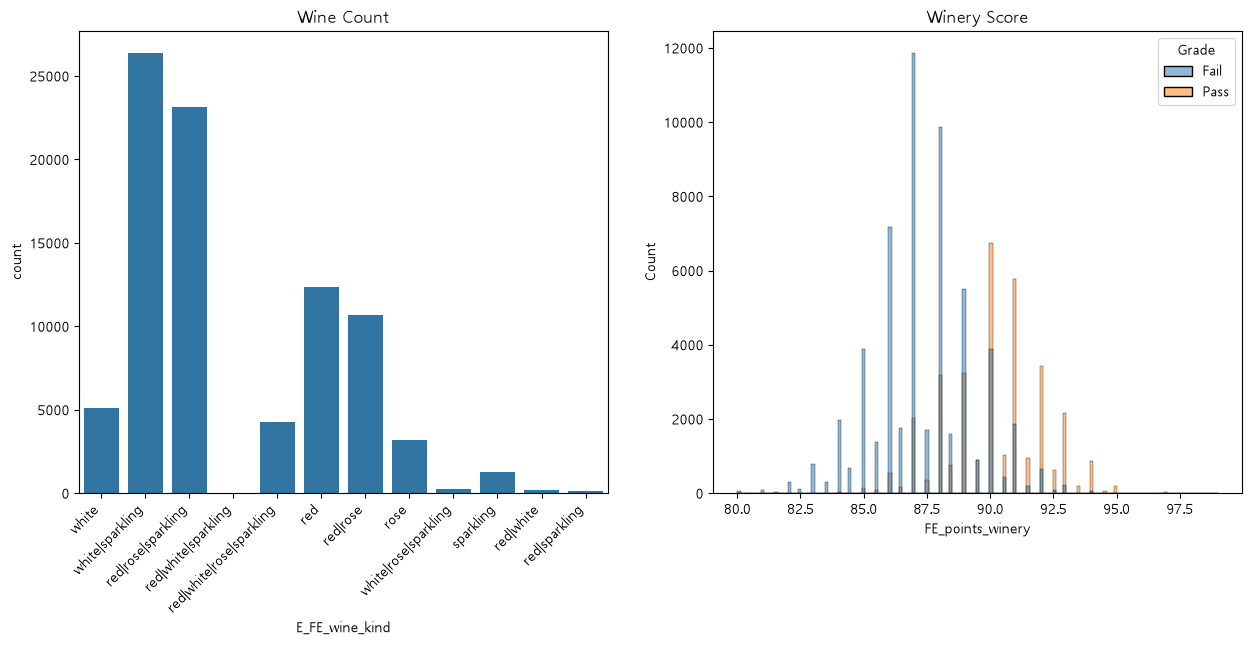

In [6]:
# [3번 샘플 문항] 아래 코드의 빈칸을 채우고 실행하세요.

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

sns.countplot(data=data, x='E_FE_wine_kind', ax=axes[0])
sns.histplot(data=data, x='FE_points_winery', hue='Grade', ax=axes[1])

plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

axes[0].set_title('Wine Count')
axes[1].set_title('Winery Score')

plt.show()

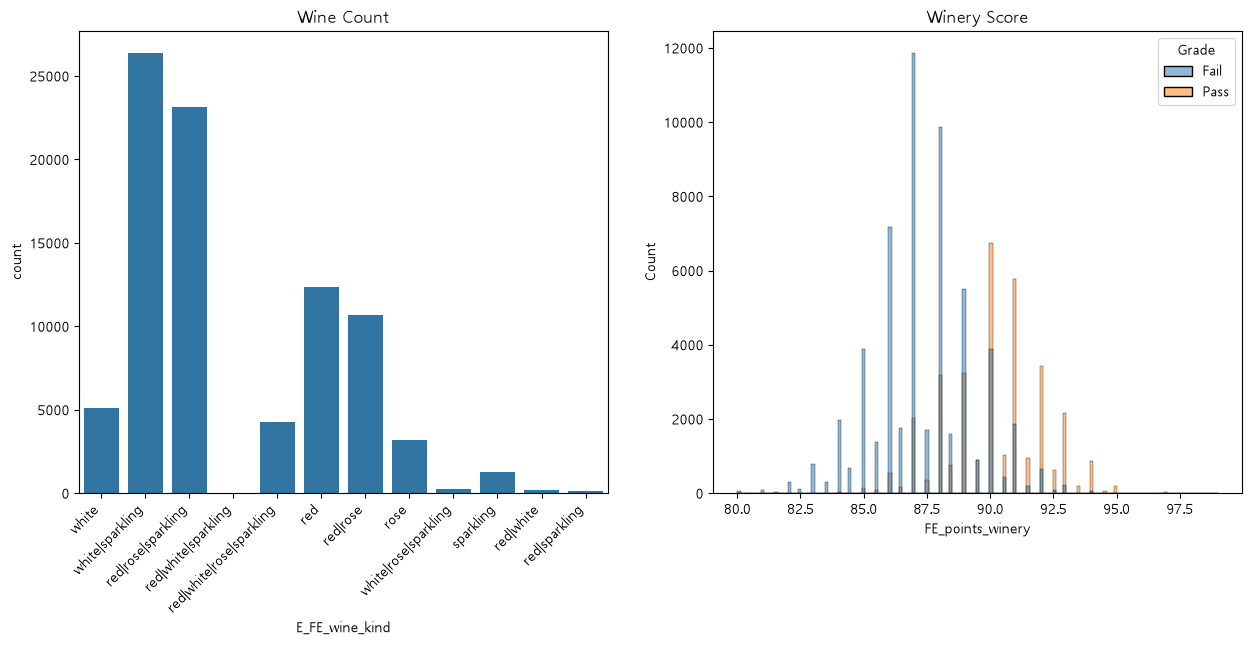

In [7]:
# [3번 샘플 코드] 

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

sns.countplot(data=data, x='E_FE_wine_kind', ax=axes[0])
sns.histplot(data=data, x='FE_points_winery', hue='Grade', ax=axes[1])

plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

axes[0].set_title('Wine Count')
axes[1].set_title('Winery Score')

plt.show()

답안3_1 = 'subplots'
답안3_2 = 'axes'
답안3_3 = 'set_title'


<br>
<br>

### **4. 그래프를 통해 와인품질등급(Grade) 별 와이너리 평점(FE_points_winery) 컬럼의 분포를 확인하려 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;아래 가이드에 따라 boxplot으로 시각화하세요.**

* **
- 대상 데이터프레임 : data
- seaborn의 boxplot으로 와이너리 평점(FE_points_winery) 컬럼의 분포를 그래프로 그려주세요.
- X축에는 와인품질등급(Grade)을, Y축에는 와이너리 평점(FE_points_winery)을 표시해 주세요.
---

<Axes: xlabel='Grade', ylabel='FE_points_winery'>

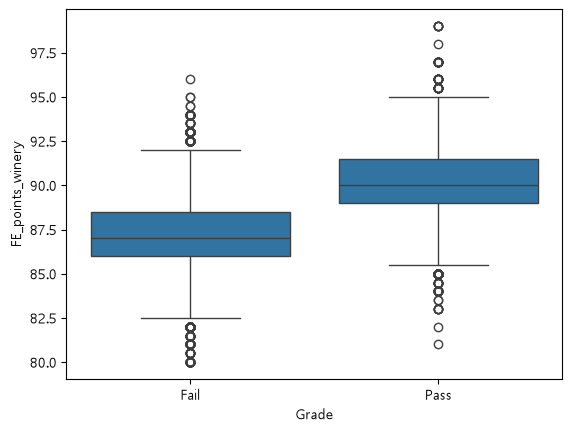

In [8]:
# [4번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.
sns.boxplot(data=data, x='Grade', y='FE_points_winery')




<Axes: xlabel='Grade', ylabel='FE_points_winery'>

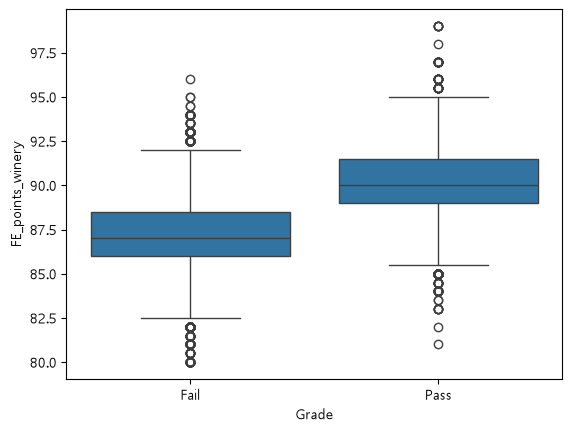

In [9]:
# [4번 샘플 코드] 


sns.boxplot(data=data, x='Grade', y='FE_points_winery')

<br>
<br>

<br>
<br>

## <font color=blue>**<데이터 전처리 (30점)>**</font>


<br>
<br>

### **5. boxplot으로 확인한 결과, 와이너리 평점(FE_points_winery) 컬럼에서 이상치가 발견되었습니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;AI모델링할때 부정적 영향이 없도록 아래 가이드에 따라 이상치를 처리하세요.**
* **
- 대상 데이터프레임 : data
- 와이너리 평점이 upperfence 값보다 큰 이상치가 있는 행(row)을 삭제하세요.
- 와이너리 평점이 lowerfence 값보다 작은 이상치가 있는 행(row)을 삭제하세요.
- AI모델링에 불필요한 와인이름(E_title) 컬럼을 삭제하세요.
- 전처리를 적용한 데이터프레임은 data_temp라는 변수명으로 저장해 주세요.
- 전처리를 완료한 뒤 index를 초기화 해주세요
- 코드의 빈칸 '< blank5-1 >', '< blank5-2 >'을 채우고, 코드를 실행하세요.
- '< blank5-1 >', '< blank5-2 > 빈칸에 들어갈 내용을 '답안5_1', '답안5_2' 변수에 저장해 주세요.
    - 예시) 답안5_0 = 'data'
---

In [10]:
# [5번 샘플 문항] 아래 코드의 빈칸을 채우고 실행하세요.

q1 = data['FE_points_winery'].quantile(0.25)
q3 = data['FE_points_winery'].quantile(0.75)

iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

data_temp = data.drop(data[(data['FE_points_winery'] > upper_fence)|(data['FE_points_winery'] < lower_fence)].index, axis = 0)
data_temp = data_temp.drop(columns = ['E_title'])
data_temp.reset_index(drop=True,inplace=True)


In [11]:
# [5번 샘플 코드] 

q1 = data['FE_points_winery'].quantile(0.25)
q3 = data['FE_points_winery'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

data_temp = data.drop( data[(data['FE_points_winery'] > upper_fence) | (data['FE_points_winery'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop( columns=['E_title'])
data_temp.reset_index(drop=True, inplace=True)

답안5_1 = 'drop'
답안5_2 = 'index'

<br>
<br>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;AI모델링할때 부정적 영향이 없도록 아래 가이드에 따라 결측치를 처리하세요.**
* **
- 대상 데이터프레임 : data_temp
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요.
- 전처리가 반영된 데이터프레임은 변수명 data_na에 저장해 주세요.
- 결측치가 사라졌는지 확인하세요.
- 코드의 빈칸 '< blank6-1 >', '< blank6-2 >' 을 채우고, 코드를 실행하세요.
- '< blank6-1 >', '< blank6-2 >' 빈칸에 들어갈 내용을 '답안6_1', '답안6_2' 변수에 저장해 주세요.
    - 예시) 답안6_0 = 'data'
---


In [12]:
# [6번 샘플 문항] 아래 코드의 빈칸을 채우고 실행하세요.

print( '결측치 처리 전\n', data_temp.isnull().sum())
data_na = data_temp.dropna()
print( '결측치 처리 후\n', data_na.isnull().sum())

결측치 처리 전
 Grade                    0
E_country                0
E_province               0
E_region_1               0
E_region_2               0
E_winery                 0
E_FE_vintage             0
E_wine_variety           0
E_FE_wine_kind        3746
FE_continent             0
E_price               6902
FE_points_location       0
FE_points_variety        0
FE_points_winery         0
dtype: int64
결측치 처리 후
 Grade                 0
E_country             0
E_province            0
E_region_1            0
E_region_2            0
E_winery              0
E_FE_vintage          0
E_wine_variety        0
E_FE_wine_kind        0
FE_continent          0
E_price               0
FE_points_location    0
FE_points_variety     0
FE_points_winery      0
dtype: int64


In [13]:
# [6번 샘플 코드] 

print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dropna()

print( '결측치 처리 후\n', data_na.isnull().sum() )





답안6_1 = 'isnull'
답안6_2 = 'dropna'

결측치 처리 전
 Grade                    0
E_country                0
E_province               0
E_region_1               0
E_region_2               0
E_winery                 0
E_FE_vintage             0
E_wine_variety           0
E_FE_wine_kind        3746
FE_continent             0
E_price               6902
FE_points_location       0
FE_points_variety        0
FE_points_winery         0
dtype: int64
결측치 처리 후
 Grade                 0
E_country             0
E_province            0
E_region_1            0
E_region_2            0
E_winery              0
E_FE_vintage          0
E_wine_variety        0
E_FE_wine_kind        0
FE_continent          0
E_price               0
FE_points_location    0
FE_points_variety     0
FE_points_winery      0
dtype: int64


<br>
<br>

### **7. 원-핫 인코딩(One-Hot Encoding)은 범주형 데이터를 1과 0의 이진형 벡터로 변환하기 위해 사용하는 방법입니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;아래 가이드에 따라 빈칸을 채우고 오류를 정정하여 범주형 데이터를 이진형 벡터로 변환하는 코드를 완성하세요.**
* **

- 대상 데이터프레임 : data_na
- 와인종류(E_FE_wine_kind) 컬럼의 값들을 아래 기준에 따라 치환하세요.
    - 'white|rose|sparkling','red|white|sparkling', 'red|white|rose|sparkling', 'red|sparkling' > 4가지 값을 'sparkling' 으로 치환
    - 'white|sparkling' > 1가지 값을 'white' 로 치환
    - 'red|rose', 'red|white', 'red|rose|sparkling' > 3가지 값을 'red' 로 치환
- 치환 후 와인종류(E_FE_wine_kind)의 카테고리 별 개수를 출력하세요.
- 불필요한 컬럼 5개('E_province', 'E_region_1', 'E_region_2', 'E_winery', 'E_wine_variety')를 삭제하세요.
- 원-핫 인코딩 대상 컬럼은 'E_country', 'E_FE_wine_kind' 2개 입니다.
- 원-핫인코딩이 반영된 결과를 데이터프레임 변수명 data_preset에 저장해 주세요.
- 원-핫인코딩한 결과, 인코딩 대상 컬럼이 변환되었는지 info 함수로 검증하세요.
- 코드의 빈칸 '< blank7-1 >' 과 '< blank7-2 >'을 채우고 코드를 실행하세요.
- data_na의 와인종류(E_FE_wine_kind) 중 'red'의 개수를 '답안7' 변수에 저장해 주세요.
    - 예시) 답안7 = 1234
---


In [14]:
# [7번 샘플 문항] 아래 코드의 빈칸을 채우고 코드를 실행하세요.

data_na.loc[data_na['E_FE_wine_kind'].isin(['white|rose|sparkling','red|white|sparkling', 'red|white|rose|sparkling', 'red|sparkling']),['E_FE_wine_kind']] = 'sparkling'
data_na.loc[data_na['E_FE_wine_kind'].isin(['white|sparkling']),['E_FE_wine_kind']] = 'white'
data_na.loc[data_na['E_FE_wine_kind'].isin(['red|rose', 'red|white', 'red|rose|sparkling']),['E_FE_wine_kind']] = 'red'
print(data_na['E_FE_wine_kind'].value_counts())

data_na = data_na.drop(columns=['E_province', 'E_region_1', 'E_region_2', 'E_winery', 'E_wine_variety'])
data_preset = pd.get_dummies(data = data_na, columns = ['E_country', 'E_FE_wine_kind'])
data_preset.info()


E_FE_wine_kind
red          42262
white        29126
sparkling     5626
rose          2910
Name: count, dtype: int64
<class 'pandas.DataFrame'>
Index: 79924 entries, 2 to 90059
Data columns (total 52 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Grade                             79924 non-null  str    
 1   E_FE_vintage                      79924 non-null  int64  
 2   FE_continent                      79924 non-null  int64  
 3   E_price                           79924 non-null  float64
 4   FE_points_location                79924 non-null  float64
 5   FE_points_variety                 79924 non-null  float64
 6   FE_points_winery                  79924 non-null  float64
 7   E_country_Argentina               79924 non-null  bool   
 8   E_country_Armenia                 79924 non-null  bool   
 9   E_country_Australia               79924 non-null  bool   
 10  E_country_Austria            

In [15]:
# # [7번 샘플 코드] 

# data_na.loc[data_na['E_FE_wine_kind'].isin(['white|rose|sparkling','red|white|sparkling', 'red|white|rose|sparkling', 'red|sparkling']), ['E_FE_wine_kind']] = 'sparkling'
# data_na.loc[data_na['E_FE_wine_kind'].isin(['white|sparkling']), ['E_FE_wine_kind']] = 'white'
# data_na.loc[data_na['E_FE_wine_kind'].isin(['red|rose', 'red|white', 'red|rose|sparkling']), ['E_FE_wine_kind']] = 'red'
# print(data_na['E_FE_wine_kind'].value_counts())


# data_na = data_na.drop(['E_province', 'E_region_1', 'E_region_2', 'E_winery', 'E_wine_variety'], axis=1)
# data_preset = pd.get_dummies(data = data_na, columns = ['E_country', 'E_FE_wine_kind'])
# data_preset.info()


# 답안7 = 42262

<br>
<br>

### **8. 모델링후에 모델의 성능을 평가할 수 있도록 훈련과 검증 각각에 사용할 데이터셋을 분리하려고 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;와인품질등급(Grade) 컬럼을 레이블값 y로, 나머지 컬럼을 피처값 X로 할당한 후 훈련데이터셋과 검증데이터셋으로 분리하세요.**
* **
- 대상 데이터프레임 : data_preset
- scikit-learn의 train_test_split 함수를 활용하세요
- 훈련과 검증데이터셋 분리
  - 훈련데이터셋 레이블 : y_train, 훈련데이터셋 피처: X_train
  - 검증데이터셋 레이블 : y_valid, 검증데이터셋 피처: X_valid
  - 훈련데이터셋과 검증데이터셋 비율은 70:30으로 설정하세요
  - 훈련데이터셋과 검증데이터셋의 와인등급 비율을 동일하게 하는 옵션을 설정하세요.
  - 난수 시드는 7로 설정하세요
---

In [16]:
# [8번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split
X = data_preset.drop(columns = ['Grade'])
y = data_preset['Grade']

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.3,random_state=7,stratify=y)

In [17]:
# [8번 샘플 코드] 

from sklearn.model_selection import train_test_split

X = data_preset.drop('Grade', axis=1)
y = data_preset['Grade']


X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)

<br>
<br>

### **9. 스케일링을 통해 데이터 이상치의 영향도를 낮추려고 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;그런데 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요.**
* **
- sklearn.preprocessing에서 StandardScaler 함수를 import하세요.
- StandardScaler 함수를 ss 변수에 지정하세요.
- 훈련데이터에 대해 StandardScaler를 학습시키고 변환을 적용하세요.
- 스케일을 반영할 변수는 스케일 반영전 변수를 그대로 사용하세요.
- 검증데이터에 학습된 스케일링 기준을 그대로 적용하세요.
- 스케일링된 검증데이터의 가장 큰 값을 찾고, 이를 반올림하세요.
- StandardScaler 적용 후 검증데이터의 최댓값을 반올림한 결과를 '답안9' 변수에 저장해 주세요.
   - 예시) 답안9 = 1234
----

In [18]:
# [9번 샘플 문항] 아래의 코드를 정정하고 실행하세요.

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

round(np.max(X_valid))

237

In [19]:
# [9번 샘플 코드]

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
round(np.max(X_valid))

답안9 = 237

<br>
<br>

<br>
<br>

## <font color=blue>**<AI 모델링(50점)>**</font>

<br>
<br>

### **10. 와인품질등급(Grade)을 예측하는 머신러닝 모델을 만들려고 합니다.** 
### **&nbsp;&nbsp;&nbsp;&nbsp;아래의 가이드에 따라 DecisionTree와 RandomForest 모델의 하이퍼파라미터를 아래와 같이 구성하는 코드를 완성하세요**




* **
- **[10-1] DecisionTree 모델의 하이퍼파라미터를 아래와 같이 구성하고, gs_dt 변수에 저장하세요**
  - Cross Validation 방법론 중 GridSearchCV 사용하여 총 3회의 Cross Validation 수행
  - 트리의 최대 깊이 후보 : [3, 5, 7, 10]
  - 노드를 분할하기 위한 최소한의 샘플 데이터수(min_samples_split) 후보 : [2, 3, 5, 10]
  - GridSearchCV의 scoring 파라미터는 'accuracy', n_jobs 파라미터는 -1 로 설정
  - DecisionTree 모델의 난수 시드 : 7
  - 앞서 분리한 훈련데이터셋으로 fit 함수를 사용해 학습시키세요<br><br>

---

In [20]:
# [10-1번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=7)

param_grid_dt = {
    'max_depth' : [3,5,7,10],
    'min_samples_split' : [2,3,5,10]
}

gs_dt = GridSearchCV(
    estimator = dt,
    param_grid = param_grid_dt,
    cv = 3,
    scoring = 'accuracy',
    n_jobs = -1
)

gs_dt.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=7), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'min_samples_split': [2, 3, 5, 10]},
             scoring='accuracy')

In [21]:
# [10-1번 샘플 코드]

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=7)

param_grid_dt = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 3, 5, 10]
}

gs_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_dt.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=7), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'min_samples_split': [2, 3, 5, 10]},
             scoring='accuracy')

---
- **[10-2] RandomForest 모델의 하이퍼파라미터를 아래와 같이 설정하고, gs_rf 변수에 저장하세요**
  - Cross Validation 방법론 중 GridSearchCV 사용하여 총 3회의 Cross Validation 수행
  - 분류기 개수 후보 : [100, 200, 500]
  - 트리의 최대 깊이 후보 : [5, 10, 20]
  - 노드를 분할하기 위한 최소한의 샘플 데이터수(min_samples_split) 후보 : [2, 5, 10]
  - GridSearchCV의 scoring 파라미터는 'accuracy', n_jobs 파라미터는 -1 로 설정
  - RandomForest 모델의 난수 시드 : 7
---

In [23]:
# [10-2번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=7)

param_grid_rf = {
    "n_estimators" : [100,200,500],
    "max_depth" : [5,10,20],
    "min_samples_split" : [2,5,10],
}

gs_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv = 3,
    scoring = "accuracy",
    n_jobs = -1,
)

gs_rf.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=7), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 500]},
             scoring='accuracy')

In [ ]:
# [10-2 샘플 코드] 

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=7)

param_grid_rf = {
    "n_estimators": [100, 200, 500],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10]
}

gs_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_rf.fit(X_train, y_train)

---

- **[10-3] Grid Search를 통해 찾아낸 RandomForest의 최적화된 분류기 개수를 '답안10' 변수에 저장해 주세요.**

---

In [24]:
# [10-3번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.
print(gs_rf.best_estimator_)
print(gs_rf.best_score_)
print(gs_rf.best_params_)
print(gs_rf.best_params_['n_estimators'])



RandomForestClassifier(max_depth=20, min_samples_split=10, n_estimators=500,
                       random_state=7)
0.8163586378101901
{'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 500}
500


In [ ]:
# [10-3번 샘플 코드] 


print(gs_rf.best_estimator_)

답안10 = 500

<br>
<br>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 RandomForest 모델의 변수중요도를 파악하려고 하는데 에러가 나고 있습니다.** 
### **&nbsp;&nbsp;&nbsp;&nbsp;아래 가이드에 따라 코드의 오류를 정정하세요.**
* **
- Grid Search를 통해 찾은 최적화된 파라미터가 적용된 gs_rf의 best_estimator를 사용하세요.
- 변수중요도 점수와 변수 이름을 매핑하여 DataFrame을 만드세요.
- 변수중요도 점수를 기준으로 top 10개만 선정하고 내림차순으로 정렬하세요.
- 변수중요도 점수를 막대 그래프로 시각화하세요.
- 출력된 그래프에서 가장 높은 중요도를 보이는 feature명을 '답안11' 변수에 저장해 주세요.
   - 예시) 답안11 = 'data'
---

<Axes: xlabel='importance', ylabel='feature'>

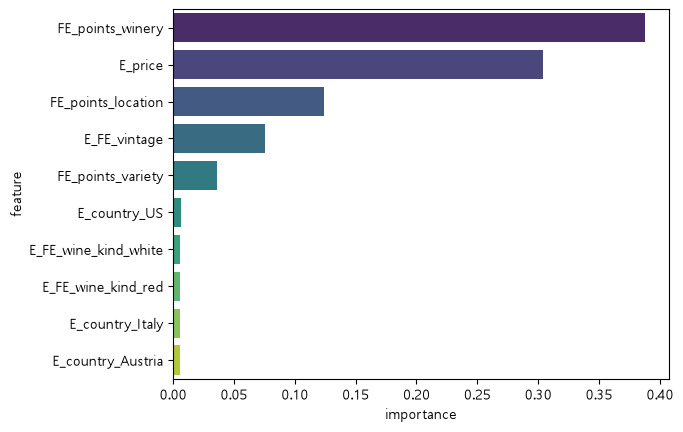

In [25]:
# [11번 샘플 문항] 아래의 코드를 정정하고 실행하세요.
# fi = pd.DataFrame({'feature': X.columns, 'importance': rf.importances})
# fi = fi.sort_index('importance', ascending=False)[:10]
# sns.barplot(x='importance', y='feature', data=fi, palette='viridis')

fi = pd.DataFrame({
        'feature' : X.columns,
        'importance' : gs_rf.best_estimator_.feature_importances_,
})

fi = fi.sort_values(['importance'], ascending=False)[:10]

sns.barplot(data=fi, x='importance', y='feature', palette='viridis')


In [ ]:
# [11번 샘플 코드] 

fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')

답안11 = 'FE_points_winery'

<br>
<br>

### **12. 앞서 학습시킨 DecisionTree와 RandomForest 모델의 성능을 평가하려고 합니다.**
### **&nbsp;&nbsp;&nbsp;&nbsp;아래 가이드에 따라 각 모델의 Accuracy를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 정정하세요.**

* **
- Grid Search를 통해 찾은 최적화된 파라미터가 적용된 gs_dt와 gs_rf의 best_estimator를 사용하세요.
- 성능 평가는 검증데이터셋을 활용하세요.
- 앞서 만든 DecisionTree 모델로 y값을 예측하고, 그 결과를 y_pred_dt 변수에 저장해 주세요.
- 검증 정답(y_valid)과 예측값(y_pred_dt)의 Accuracy를 구하고 dt_acc 변수에 저장해 주세요.
- 앞서 만든 RandomForest 모델로 y값을 예측하고, 그 결과를 y_pred_rf에 저장해 주세요.
- 검증 정답(y_valid)과 예측값(y_pred_rf)의 Accuracy를 구하고 rf_acc 변수에 저장해 주세요.
- 2개 모델의 Accuracy값을 출력하세요.
- 두 모델의 Accuracy 결과를 비교했을 때, 성능이 더 우수한 모델의 이름을 '답안12' 변수에 저장해 주세요.
  - 예시) 답안12 = 'model'
---

In [26]:
# [12번 샘플 문항] 아래의 코드를 정정하고 실행하세요.
# from sklearn.metrics import accuracy
# y_pred_dt = dt.pred(X_valid)
# y_pred_rf = rf.pred(X_valid)
# dt_acc = accuracy(y_valid, y_pred_dt)
# rf_acc = accuracy(y_valid, y_pred_rf)
# print("DecisionTree_acc = ", dt_acc)
# print("RandomForest_acc = ", rf_acc)

from sklearn.metrics import accuracy_score

y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)

dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)

print("DecisionTree_acc = ", dt_acc)
print("RandomForest_acc = ", rf_acc)



DecisionTree_acc =  0.8095337392609893
RandomForest_acc =  0.8173742597380933


In [ ]:
# [12 샘플 코드]

from sklearn.metrics import accuracy_score

y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)

dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)

print("DecisionTree_acc = ", dt_acc)
print("RandomForest_acc = ", rf_acc)


답안12 = 'RandomForest'

<br>
<br>

<br>
<br>

### **13. 와인품질등급(Grade)을 예측하는 딥러닝 모델을 만들려고 합니다.**
### **아래 토폴로지 다이어그램과 가이드를 참고해서 모델링하고 학습을 수행하세요.**
* **
- tensorflow framework를 사용하고 하단의 토폴로지 그림과 동일한 딥러닝 모델을 구현하세요.
- 히든 레이어의 activation 함수는 'relu'를, 마지막 아웃풋 레이어의 activation 함수는 'sigmoid'를 사용하세요.
- EarlyStopping 함수를 사용해서 14번의 epoch 동안 모니터링 지표(val_loss)가 향상되지 않을 경우 훈련을 중지하도록 설정하고 estop 변수에 저장하세요.
- y_train, y_valid 변수의 값을 LabelEncoder를 사용하여 정수의 형태로 변환하세요.
- 정수 형태의 범주형 값으로 변환된 y_train, y_valid 변수를 to_categorical 함수를 사용하여 One-Hot Encoding 형태로 변환하세요.
- optimizer는 adam, metrics는 accuracy, loss는 binary_crossentropy로 지정해서 모델을 컴파일하세요.
- 다음 조건에 따라 모델을 학습하고 학습정보는 history 변수에 저장하세요.
    - batch_size : 128
    - epoch : 30
- 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- 코드의 빈칸 '< blank13-1 >' 과 '< blank13-2 >'을 채우고 코드를 실행하세요.

---

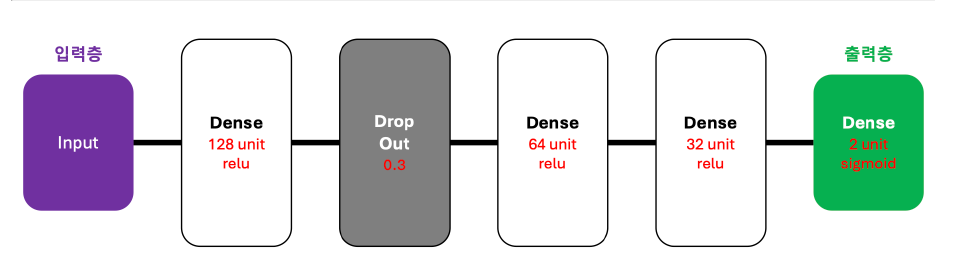

<br>
<br>

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**
>

In [ ]:
# %pip install tensorflow

In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

<br>
<br>

In [28]:
# [13번 샘플 문항] 아래 코드의 빈칸을 채우고 실행하세요.

from sklearn.preprocessing import LabelEncoder

# model = Sequential([
#     < blank13-1 >
# ])

# estop = EarlyStopping(monitor='val_loss', < blank13-2 > = 14)
# model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# le = LabelEncoder()
# y_train = le.fit_transform(y_train)
# y_valid = le.transform(y_valid)

# y_train = to_categorical(y_train)
# y_valid = to_categorical(y_valid)

# history = model.fit(X_train, y_train,
#                      epochs=30,
#                      batch_size=128,
#                      validation_data=(X_valid, y_valid),
#                      callbacks=[estop])

model = Sequential([
    Dense(128, activation='relu', input_dim = X_train.shape[1]),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid'),
])

estop = EarlyStopping(monitor='val_loss', patience=14)
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_valid = le.transform(y_valid)

y_train = to_categorical(y_train)
y_valid = to_categorical(y_valid)

history = model.fit(X_train, y_train,
                    epochs = 30,
                    batch_size = 128,
                    validation_data = (X_valid,y_valid),
                    callbacks=[estop])

Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7873 - loss: 0.4524 - val_accuracy: 0.8088 - val_loss: 0.4145
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8034 - loss: 0.4200 - val_accuracy: 0.8119 - val_loss: 0.4102
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8065 - loss: 0.4160 - val_accuracy: 0.8126 - val_loss: 0.4083
Epoch 4/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8085 - loss: 0.4120 - val_accuracy: 0.8131 - val_loss: 0.4050
Epoch 5/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8094 - loss: 0.4091 - val_accuracy: 0.8135 - val_loss: 0.4056
Epoch 6/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8114 - loss: 0.4077 - val_accuracy: 0.8144 - val_loss: 0.4055
Epoch 7/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8115 - loss: 0.4066 - val_accuracy: 0.8140 - val_loss: 0.4046
Epoch 8/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8106 - loss: 0.4049 - val_accuracy: 0.

In [ ]:
# [13번 샘플 코드]

from sklearn.preprocessing import LabelEncoder

model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_valid = le.transform(y_valid)

y_train= to_categorical(y_train)
y_valid = to_categorical(y_valid)

history = model.fit(X_train, y_train,
                     epochs=30,
                     batch_size=128,
                     validation_data=(X_valid, y_valid),
                     callbacks=[estop])

<br>
<br>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능(Generalization Performance)을 평가하려고 합니다.**
### **matplotlib 라이브러리 활용해서, 학습 Accuracy와 검증 Accuracy의 변화를 그래프로 시각화하세요.**
* **
- 아래 가이드에 따라 Accuracy 변화를 시각화하는 코드를 완성하세요
    - 1개의 그래프에 학습 Accuracy과 검증 Accuracy 2가지를 모두 표시하세요
    - 위 2가지 각각의 범례를 'acc', 'val_acc'로 표시하세요
    - 그래프의 타이틀은 'Model Accuracy'로 표시하세요
    - X축에는 'Epoch'라고 표시하고 Y축에는 'Accuracy'라고 표시하세요<br><br>
---

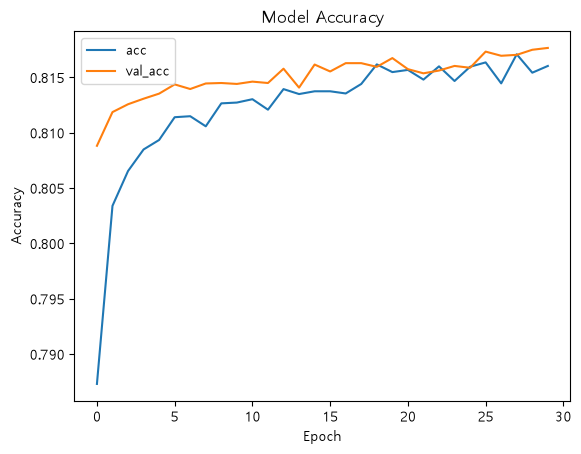

In [29]:
# [14번 샘플 문항] 여기에 답안코드를 작성하고 실행하세요.

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['acc', 'val_acc'])
plt.show() 



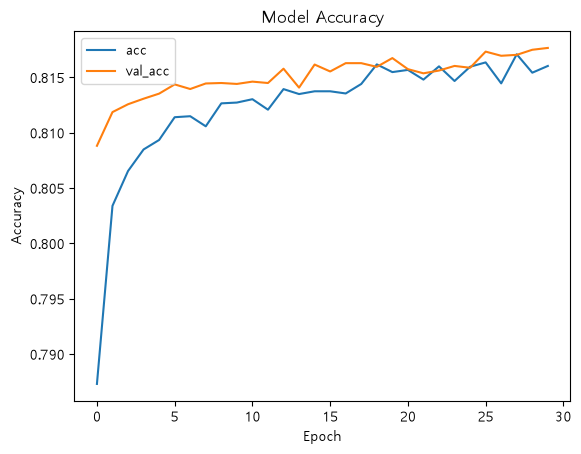

In [30]:
# [14 샘플 코드]

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['acc', 'val_acc'])
plt.show() 

<br>
<br>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### **'최종제출 및 종료'를 클릭하셔서 답안을 제출해 주시기 바랍니다.**